# **Experimental Demonstration of Variational Quantum Eigensolver (VQE)**

# **Aim**:

To study and implement the Variational Quantum Eigensolver (VQE) algorithm to find the ground state energy of a 1-qubit Hamiltonian ($H = 0.5 X + 1.0 Z$) using a parameterized ansatz.

# Theory:

 Variational Quantum Algorithms (VQAs) are hybrid quantum-classical algorithms designed for NISQ devices that leverage the Rayleigh–Ritz variational principle ($E_0 \le \langle \psi(\theta) | H | \psi(\theta) \rangle$) to estimate ground-state energies23.

  VQE parameterizes a trial state $|\psi(\theta)\rangle$ using a quantum circuit ansatz (such as $Ry(\theta)$) and evaluates expectation values of Hamiltonian Pauli terms on quantum hardware3.
  
  A classical optimizer iteratively updates the parameters $\theta$ to minimize energy until convergence, achieving noise resilience and near-term quantum advantage for molecular and materials simulation34.

# Prerequisites & Package Installation

 Run this cell to install Qiskit, the Aer simulation framework, NumPy and Matplotlib for plotting measurement results.

In [ ]:
# Environment setup and dependencies
!pip install qiskit qiskit-aer matplotlib numpy

# Core module imports
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

# **Program Code:**

=== Variational Quantum Eigensolver (VQE) Study ===
Hamiltonian Operator:
SparsePauliOp(['X', 'Z'],
              coeffs=[0.5+0.j, 1. +0.j])

Exact Analytical Ground State Energy: -1.118034

Scanning parameter space over θ ∈ [0, 2π]...
VQE Minimum Energy Found: -1.117949 at θ = 3.6176 radians



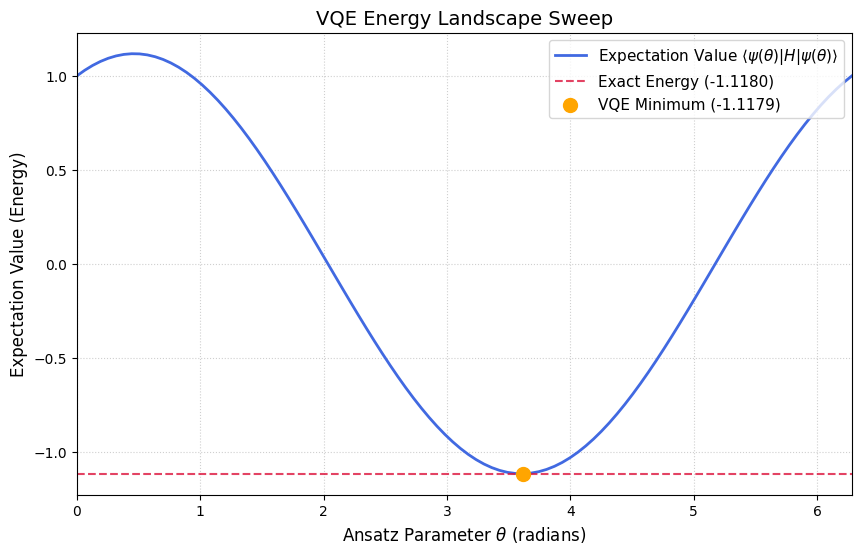

In [12]:
def run_vqe_study():
    print("=== Variational Quantum Eigensolver (VQE) Study ===")

    # 1. Define a 1-qubit Hamiltonian (H = 0.5 * X + 1.0 * Z)
    H = SparsePauliOp(["X", "Z"], coeffs=[0.5, 1.0])
    print(f"Hamiltonian Operator:\n{H}\n")

    # Compute the exact ground state energy using classical diagonalization for reference
    H_matrix = H.to_matrix()
    exact_eigenvalues = np.linalg.eigvals(H_matrix).real
    exact_energy = min(exact_eigenvalues)
    print(f"Exact Analytical Ground State Energy: {exact_energy:.6f}\n")

    # 2. Define the parameter space for the Ry(theta) ansatz
    thetas = np.linspace(0, 2 * np.pi, 100)
    energies = []

    print("Scanning parameter space over θ ∈ [0, 2π]...")
    for theta in thetas:
        # Construct the parameterized ansatz state |psi(θ)>
        qc = QuantumCircuit(1)
        qc.ry(theta, 0)
        state = Statevector.from_instruction(qc)

        # Compute expectation value: <psi(θ)| H |psi(θ)>
        expectation_value = state.expectation_value(H).real
        energies = np.append(energies, expectation_value)

    # Find the optimal angle and the corresponding minimum energy found
    vqe_min_idx = np.argmin(energies)
    vqe_min_energy = energies[vqe_min_idx]
    vqe_opt_theta = thetas[vqe_min_idx]

    print(f"VQE Minimum Energy Found: {vqe_min_energy:.6f} at θ = {vqe_opt_theta:.4f} radians\n")

    # 3. Visualization
    plt.figure(figsize=(10, 6))
    plt.plot(thetas, energies, label=r"Expectation Value $\langle \psi(\theta) | H | \psi(\theta) \rangle$", color='royalblue', linewidth=2)
    plt.axhline(y=exact_energy, color='crimson', linestyle='--', label=f"Exact Energy ({exact_energy:.4f})", alpha=0.8)
    plt.scatter(vqe_opt_theta, vqe_min_energy, color='orange', s=100, zorder=5, label=f"VQE Minimum ({vqe_min_energy:.4f})")

    plt.title("VQE Energy Landscape Sweep", fontsize=14)
    plt.xlabel(r"Ansatz Parameter $\theta$ (radians)", fontsize=12)
    plt.ylabel("Expectation Value (Energy)", fontsize=12)
    plt.xlim(0, 2 * np.pi)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc="upper right", fontsize=11)
    plt.show()

# Run the executable VQE program
run_vqe_study()

### 📊 Experimental Results

The plot illustrates the hybrid quantum-classical parameter optimization landscape for the 1-qubit Hamiltonian $H = 0.5 X + 1.0 Z$:

* **Energy Landscape Curve (Blue)**: Maps the expectation value $\langle \psi(\theta) | H | \psi(\theta) \rangle$ as a smooth continuous function of the variational parameter $\theta \in [0, 2\pi]$.
* **Exact Analytical Ground State (Red dashed line)**: Represents the classical minimum eigenvalue calculated via matrix diagonalization ($E_0 \approx -1.118034$).
* **VQE Minimum (Orange dot)**: Marks the optimal parameter discovered during the sweep ($\theta \approx 3.6176$ rad), yielding a minimum variational energy of $E \approx -1.117949$. This closely matches the analytical ground state, demonstrating VQE's precision.

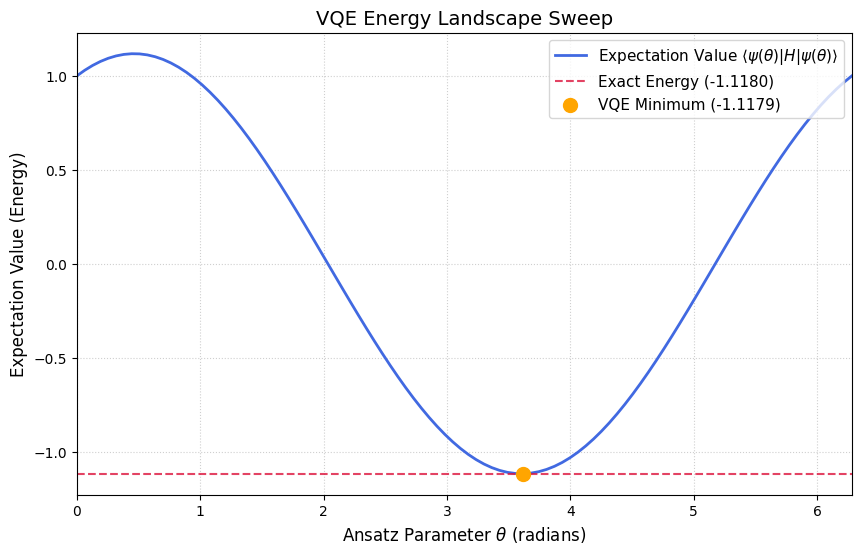

# **Observation**:

The VQE demonstration successfully maps the expectation value landscape over the parameter range $\theta \in [0, 2\pi]$. By sweeping the ansatz parameter, we identify an energy minimum of $E \approx -1.117949$ near $\theta \approx 3.6176$, closely approximating the exact analytical ground state energy of $-1.118034$ obtained via classical diagonalization.